> **1- Importation des packages**




In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import tensorflow as tf
from tensorflow import keras
from keras.datasets import cifar10
from keras.utils import to_categorical
from keras import Sequential
from keras.layers import Dense, Activation, Flatten, Conv2D, MaxPooling2D, Dropout, GlobalAveragePooling2D
from keras.applications.vgg16 import VGG16
from keras.models import Model
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping 
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import seaborn as sn
from sklearn.metrics import classification_report
from keras.models import load_model

> **2- Chargement de la base de données CIFAR10**

Le jeu de données CIFAR-10 (Canadian Institute For Advanced Research) contient 60 000 images couleur de taille 32x32 réparties en 10 classes différentes, avec 6000 images dans chaque classe. Cet ensemble d’images est divisé en 2 sous-ensembles : un ensemble pour l’entraînement qui contient 50 000 images et ensemble pour le test qui contient 10 000 images.
Les classes de cette base de données sont :


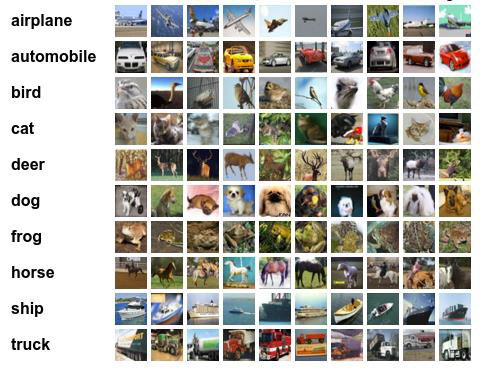

In [6]:
# charge le jeu de données CIFAR-10 et le divise en deux ensembles : un pour l'entraînement et un pour le test.
(X_train, y_train), (X_test, y_test) = cifar10.load_data() 

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 683s 4us/step


> **3- Prétraitement des données**

**Affichage du shape de l'ensemble des données**

In [ ]:
print("X_train = ", X_train.shape)
print("X_test = ", X_test.shape)
print("y_train = ", y_train.shape)
print("y_test = ", y_test.shape)

X_train =  (50000, 32, 32, 3)
X_test =  (10000, 32, 32, 3)
y_train =  (50000, 1)
y_test =  (10000, 1)


**Affichage d'un exemplaire d'images de notre ensemble d'entrainement**

In [ ]:
classes = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

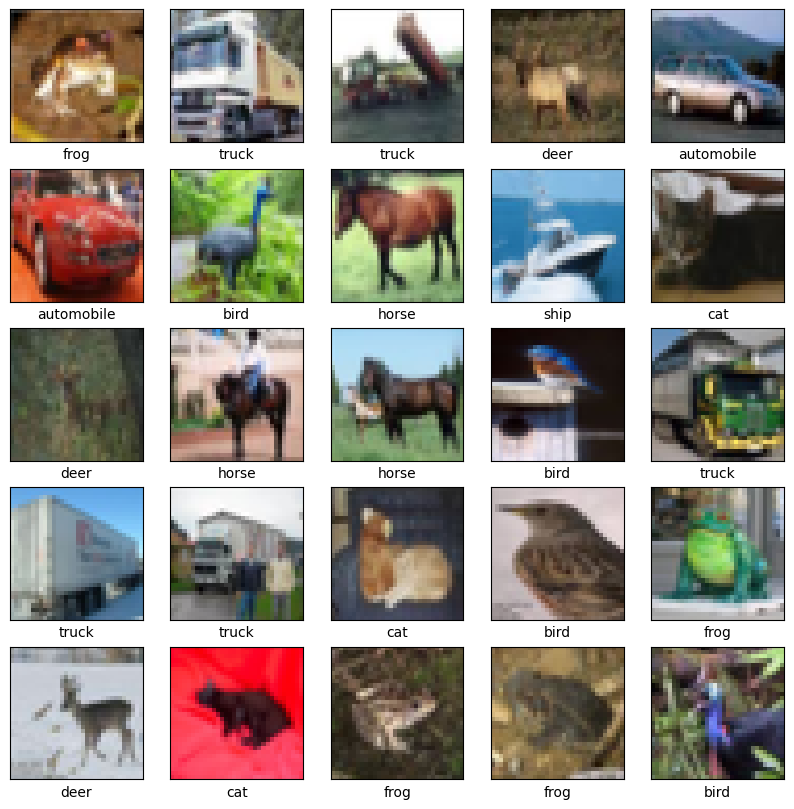

In [ ]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train[i])
    plt.xlabel(classes[y_train[i][0]])
plt.show()

**Normalisation des données d'entrée**

Cela a pour but de faciliter et augmenter la vitesse de convergence de l'algorithme. Autrement dit, pour améliorer la performance de notre modèle

In [ ]:
#Les pixels sont normalisés de la plage [0, 255] à [0, 1]
X_train = X_train / 255.0
X_test = X_test / 255.0

In [ ]:
#X_train[0] retourne l'image à l'index 0.
X_train[0]

array([[[0.23137255, 0.24313725, 0.24705882],
        [0.16862745, 0.18039216, 0.17647059],
        [0.19607843, 0.18823529, 0.16862745],
        ...,
        [0.61960784, 0.51764706, 0.42352941],
        [0.59607843, 0.49019608, 0.4       ],
        [0.58039216, 0.48627451, 0.40392157]],

       [[0.0627451 , 0.07843137, 0.07843137],
        [0.        , 0.        , 0.        ],
        [0.07058824, 0.03137255, 0.        ],
        ...,
        [0.48235294, 0.34509804, 0.21568627],
        [0.46666667, 0.3254902 , 0.19607843],
        [0.47843137, 0.34117647, 0.22352941]],

       [[0.09803922, 0.09411765, 0.08235294],
        [0.0627451 , 0.02745098, 0.        ],
        [0.19215686, 0.10588235, 0.03137255],
        ...,
        [0.4627451 , 0.32941176, 0.19607843],
        [0.47058824, 0.32941176, 0.19607843],
        [0.42745098, 0.28627451, 0.16470588]],

       ...,

       [[0.81568627, 0.66666667, 0.37647059],
        [0.78823529, 0.6       , 0.13333333],
        [0.77647059, 0

In [ ]:
## y_train contient les étiquettes (labels) des images du jeu de données d'entraînement.
y_train

array([[6],
       [9],
       [9],
       ...,
       [9],
       [1],
       [1]], dtype=uint8)

In [ ]:
## Aplatit les tableaux d'étiquettes y_train et y_test.
y_train, y_test = y_train.flatten(), y_test.flatten()

In [ ]:
y_train

array([6, 9, 9, ..., 9, 1, 1], dtype=uint8)

**Conversion des targets (étiquettes) en One hot encoding**
Chaque étiquette numérique est transformée en un vecteur binaire où seule la position correspondant à la classe de l'image est à 1.

In [ ]:
from keras.utils import to_categorical

y_train = to_categorical(y_train,10) #nous avons 10 classes
y_test = to_categorical(y_test,10)

In [ ]:
y_train[0]

array([0., 0., 0., 0., 0., 0., 1., 0., 0., 0.], dtype=float32)

> **4- Conception de notre modèle on utilisant le concept de transfer learning**

**a) Chargement du modele de base pré-entrainé (le modele VGG16)**

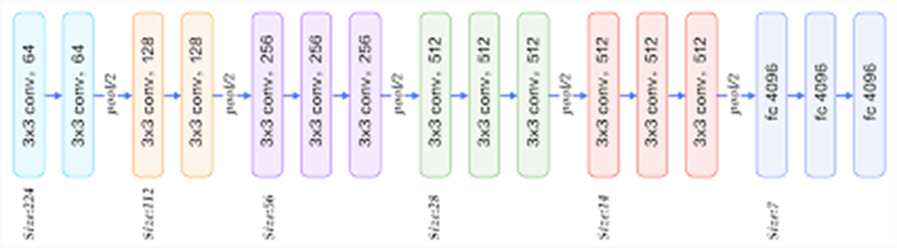

In [ ]:
from keras.applications.vgg16 import VGG16
base_model = VGG16(weights='imagenet', #les poids seront ceux estimés sur la base dImageNet
                   include_top=False, #les couches de classification de VGG ne seront pas chargées
                   input_shape=(32, 32, 3)) #shape de nos images d'entrée

58889256/58889256 [==============================] - 0s 0us/step


#**Question :** vérifier la taille de sortie et le nombre de poids à apprendre pour chaque couche.

In [ ]:
base_model.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 32, 32, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 32, 32, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 16, 16, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 16, 16, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 16, 16, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 8, 8, 128)         0     

**b) Geler les couches du modele de base VGG16**

In [ ]:
for layer in base_model.layers:
  layer.trainable = False

In [ ]:
base_model.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 block1_conv1 (Conv2D)       (None, 32, 32, 64)        1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 32, 32, 64)        36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 16, 16, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 16, 16, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 16, 16, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 8, 8, 128)         0     

c) **Notre modèle composé de la partie VGG16 et la nouvelle partie de classification (ajout de nouvelles couches Dense)**

In [ ]:
VGG_model = Sequential()
VGG_model.add(base_model)
VGG_model.add(Flatten())
VGG_model.add(Dense(64, activation='relu'))
VGG_model.add(Dense(10, activation='softmax'))

VGG_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 1, 1, 512)         14714688  
                                                                 
 flatten (Flatten)           (None, 512)               0         
                                                                 
 dense (Dense)               (None, 64)                32832     
                                                                 
 dense_1 (Dense)             (None, 10)                650       
                                                                 
Total params: 14748170 (56.26 MB)
Trainable params: 33482 (130.79 KB)
Non-trainable params: 14714688 (56.13 MB)
_________________________________________________________________


> **5- Compilation de notre modèle en utilisant le transfert d'apprentissage (Transfer Learning).
**

In [ ]:
VGG_model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

> **6- Entrainement du modele**

In [ ]:
from keras.callbacks import EarlyStopping
E_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

In [ ]:
# Entraînement du modèle VGG sur le jeu de données d'entraînement (X_train, y_train) pendant 20 époques,
# avec un batch_size de 32. La validation est effectuée à chaque époque sur le jeu de test (X_test, y_test).
# Le callback"E_stop"est utilisé pour appliquer l'arrêt anticipé (early stopping)si la performance du modèle ne s'améliore plus.
VGGmodel_history = VGG_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test),
                                 callbacks=[E_stop])

Epoch 1/20
1563/1563 [==============================] - 21s 11ms/step - loss: 1.4004 - accuracy: 0.5137 - val_loss: 1.2636 - val_accuracy: 0.5592
Epoch 2/20
1563/1563 [==============================] - 16s 11ms/step - loss: 1.2071 - accuracy: 0.5808 - val_loss: 1.2005 - val_accuracy: 0.5785
Epoch 3/20
1563/1563 [==============================] - 16s 10ms/step - loss: 1.1557 - accuracy: 0.5970 - val_loss: 1.1673 - val_accuracy: 0.5879
Epoch 4/20
1563/1563 [==============================] - 16s 10ms/step - loss: 1.1219 - accuracy: 0.6082 - val_loss: 1.1645 - val_accuracy: 0.5917
Epoch 5/20
1563/1563 [==============================] - 16s 10ms/step - loss: 1.0967 - accuracy: 0.6161 - val_loss: 1.1587 - val_accuracy: 0.5979
Epoch 6/20
1563/1563 [==============================] - 16s 10ms/step - loss: 1.0732 - accuracy: 0.6239 - val_loss: 1.1622 - val_accuracy: 0.5946
Epoch 7/20
1563/1563 [==============================] - 16s 10ms/step - loss: 1.0557 - accuracy: 0.6305 - val_loss: 1.1469 -

> **7- Evaluation du modele sur les données de test**

In [ ]:
VGG_model.evaluate(X_test,y_test)

313/313 [==============================] - 3s 8ms/step - loss: 1.1322 - accuracy: 0.6113


[1.1322388648986816, 0.611299991607666]

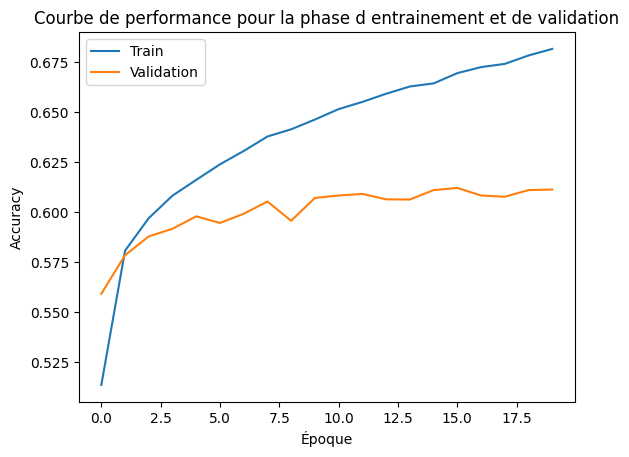

In [ ]:
acc_curve = VGGmodel_history.history['accuracy']
accV_curve = VGGmodel_history.history['val_accuracy']

plt.plot(acc_curve, label='Train')
plt.plot(accV_curve, label='Validation')


plt.title('Courbe de performance pour la phase d entrainement et de validation')
plt.xlabel('Époque')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

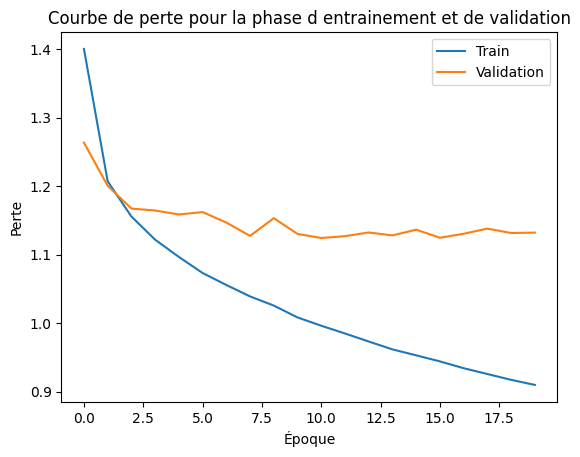

In [ ]:
loss1_curve = modelCNN1_history.history['loss1']
loss2_curve = modelCNN2_history.history['loss2']

plt.plot(loss1_curve, label='Train_CNN1')
plt.plot(loss2_curve, label='Train_CNN2')

plt.title('Courbe de perte pour la phase d entrainement du model 1 et 2')
plt.xlabel('Époque')
plt.ylabel('Perte')
plt.legend()

plt.show()

> **8- Predictions sur les données de test et analyse des performances**


In [ ]:
y_predicted = VGG_model.predict(X_test)

313/313 [==============================] - 2s 7ms/step


Text(95.72222222222221, 0.5, 'Truth')

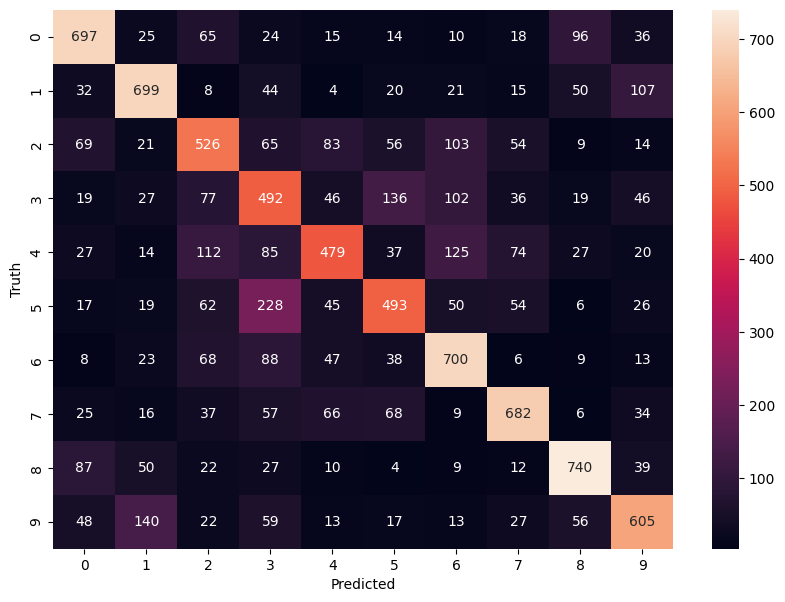

In [ ]:
y_predicted_labels = [np.argmax(i) for i in y_predicted]
cm = tf.math.confusion_matrix(labels=np.argmax(y_test, axis=1),predictions=y_predicted_labels)


plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

**Rapport de classification :**

La précision mesure la proportion d'instances correctement prédites parmi toutes les instances prédites comme appartenant à cette classe.

Précision = VP / (VP + FP)

Le rappel mesure la proportion d'instances correctement prédites parmi toutes les instances réellement appartenant à cette classe.
  
Rappel = VP / (VP + FN)

Score F1 : C'est la moyenne harmonique de la précision et du rappel. Il mesure l'équilibre entre la précision et le rappel.

F1 = 2 * (Précision * Rappel) / (Précision + Rappel)

Support : C'est le nombre réel d'instances de la classe dans l'ensemble de données de test.

In [ ]:
print("test" ,classification_report(np.argmax(y_test, axis=1), np.argmax(y_predicted, axis=1)))

test               precision    recall  f1-score   support

           0       0.68      0.70      0.69      1000
           1       0.68      0.70      0.69      1000
           2       0.53      0.53      0.53      1000
           3       0.42      0.49      0.45      1000
           4       0.59      0.48      0.53      1000
           5       0.56      0.49      0.52      1000
           6       0.61      0.70      0.65      1000
           7       0.70      0.68      0.69      1000
           8       0.73      0.74      0.73      1000
           9       0.64      0.60      0.62      1000

    accuracy                           0.61     10000
   macro avg       0.61      0.61      0.61     10000
weighted avg       0.61      0.61      0.61     10000



> **9- Sauvegarder le modele**

In [ ]:
# Sauvegarde le modèle VGG entraîné dans un fichier au format HDF5 (.h5).Cela permet de conserver l'architecture, 
#les poids et les configurations du modèle pour une utilisation ultérieure ou pour un déploiement.
VGG_model.save('modelVGG_TL.h5')
#model = load_model('modelVGG_TL.h5')

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


> **Fine_tunning : Amélioration des performances du modele**

Nous pourrions débloquer quelques couches dans le modèle pré-entrainé et le ré-entrainé davantage avec un taux d'apprentissage très faible pour affiner le modèle pour notre tâche spécifique






In [ ]:
base_modelFT = VGG16(weights='imagenet', #les poids seront ceux estimés sur la base dImageNet
                   include_top=False, #les couches de classification de VGG ne seront pas chargées
                   input_shape=(32, 32, 3)) #shape de nos images d'entrée

In [ ]:
VGG_modelFT = Sequential()
VGG_modelFT.add(base_modelFT)
VGG_modelFT.add(Flatten())
VGG_modelFT.add(Dense(64, activation='relu'))
VGG_modelFT.add(Dense(10, activation='softmax'))

VGG_modelFT.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 1, 1, 512)         14714688  
                                                                 
 flatten_2 (Flatten)         (None, 512)               0         
                                                                 
 dense_4 (Dense)             (None, 64)                32832     
                                                                 
 dense_5 (Dense)             (None, 10)                650       
                                                                 
Total params: 14748170 (56.26 MB)
Trainable params: 14748170 (56.26 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
for layer in base_modelFT.layers:
  layer.trainable = True

VGG_modelFT.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 vgg16 (Functional)          (None, 1, 1, 512)         14714688  
                                                                 
 flatten_2 (Flatten)         (None, 512)               0         
                                                                 
 dense_4 (Dense)             (None, 64)                32832     
                                                                 
 dense_5 (Dense)             (None, 10)                650       
                                                                 
Total params: 14748170 (56.26 MB)
Trainable params: 14748170 (56.26 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [ ]:
VGG_modelFT.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
E_stop1 = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
VGGmodelFT_history = VGG_modelFT.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), callbacks=[E_stop1])

Epoch 1/20
1563/1563 [==============================] - 53s 31ms/step - loss: 0.8636 - accuracy: 0.7018 - val_loss: 0.6393 - val_accuracy: 0.7848
Epoch 2/20
1563/1563 [==============================] - 47s 30ms/step - loss: 0.4949 - accuracy: 0.8333 - val_loss: 0.5202 - val_accuracy: 0.8259
Epoch 3/20
1563/1563 [==============================] - 47s 30ms/step - loss: 0.3503 - accuracy: 0.8822 - val_loss: 0.4791 - val_accuracy: 0.8438
Epoch 4/20
1563/1563 [==============================] - 47s 30ms/step - loss: 0.2468 - accuracy: 0.9166 - val_loss: 0.4622 - val_accuracy: 0.8537
Epoch 5/20
1563/1563 [==============================] - 48s 30ms/step - loss: 0.1742 - accuracy: 0.9413 - val_loss: 0.5763 - val_accuracy: 0.8359
Epoch 6/20
1563/1563 [==============================] - 48s 31ms/step - loss: 0.1240 - accuracy: 0.9591 - val_loss: 0.5707 - val_accuracy: 0.8473
Epoch 7/20
1563/1563 [==============================] - 48s 30ms/step - loss: 0.0967 - accuracy: 0.9681 - val_loss: 0.6119 -

In [ ]:
VGG_modelFT.evaluate(X_test,y_test)

313/313 [==============================] - 3s 9ms/step - loss: 0.5603 - accuracy: 0.8618


[0.560272753238678, 0.8618000149726868]

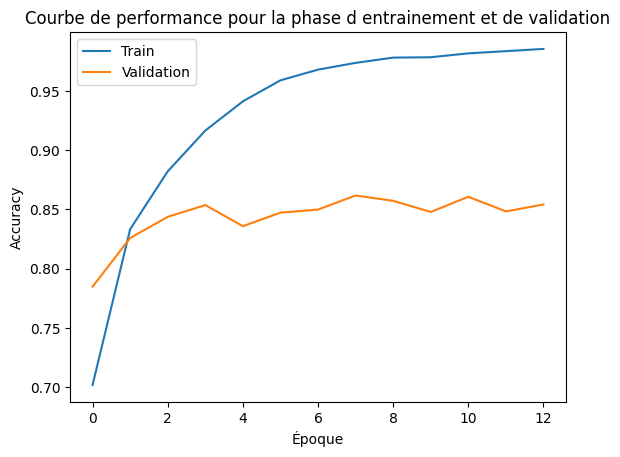

In [ ]:
acc_curveFT = VGGmodelFT_history.history['accuracy']
accV_curveFT = VGGmodelFT_history.history['val_accuracy']

plt.plot(acc_curveFT, label='Train')
plt.plot(accV_curveFT, label='Validation')


plt.title('Courbe de performance pour la phase d entrainement et de validation')
plt.xlabel('Époque')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

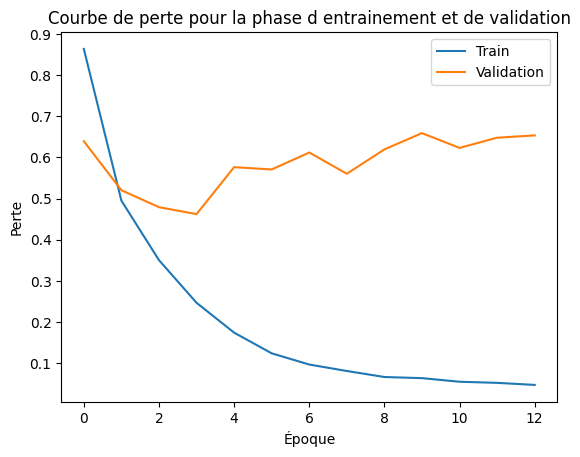

In [ ]:
loss_curveFT = VGGmodelFT_history.history['loss']
lossV_curveFT = VGGmodelFT_history.history['val_loss']

plt.plot(loss_curveFT, label='Train')
plt.plot(lossV_curveFT, label='Validation')


plt.title('Courbe de perte pour la phase d entrainement et de validation')
plt.xlabel('Époque')
plt.ylabel('Perte')
plt.legend()

plt.show()

**ImageDataGenerator de Keras,** utilisée pour effectuer des transformations sur les images, telles que la rotation, le redimensionnement, le changement de luminosité, etc., pour enrichir et diversifier les données d'entraînement.

**La méthode flow()** crée un générateur qui produit des lots d'images (batch) et d'étiquettes à partir des données d'entraînement (X_train et y_train) fournis.

In [ ]:
batch_size = 32
from keras.preprocessing.image import ImageDataGenerator
data_generator = ImageDataGenerator(
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range = 0.2)


train_generator = data_generator.flow(X_train, y_train, batch_size)
steps_per_epoch = X_train.shape[0] // batch_size

In [ ]:
E_stop1 = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
VGGmodelFT_history = VGG_modelFT.fit(train_generator, epochs=20, validation_data=(X_test, y_test), callbacks=[E_stop1])

Epoch 1/20
1563/1563 [==============================] - 64s 35ms/step - loss: 0.9587 - accuracy: 0.6675 - val_loss: 0.6700 - val_accuracy: 0.7721
Epoch 2/20
1563/1563 [==============================] - 52s 33ms/step - loss: 0.6220 - accuracy: 0.7875 - val_loss: 0.6150 - val_accuracy: 0.7958
Epoch 3/20
1563/1563 [==============================] - 52s 33ms/step - loss: 0.5238 - accuracy: 0.8220 - val_loss: 0.4679 - val_accuracy: 0.8443
Epoch 4/20
1563/1563 [==============================] - 51s 33ms/step - loss: 0.4498 - accuracy: 0.8474 - val_loss: 0.4251 - val_accuracy: 0.8565
Epoch 5/20
1563/1563 [==============================] - 51s 33ms/step - loss: 0.4031 - accuracy: 0.8626 - val_loss: 0.4301 - val_accuracy: 0.8567
Epoch 6/20
1563/1563 [==============================] - 51s 32ms/step - loss: 0.3579 - accuracy: 0.8786 - val_loss: 0.4050 - val_accuracy: 0.8669
Epoch 7/20
1563/1563 [==============================] - 52s 33ms/step - loss: 0.3290 - accuracy: 0.8883 - val_loss: 0.4130 -

In [ ]:
y_predictedFT = VGG_modelFT.predict(X_test)

313/313 [==============================] - 3s 7ms/step


In [ ]:
from sklearn.metrics import classification_report
print("test" ,classification_report(np.argmax(y_test, axis=1), np.argmax(y_predictedFT, axis=1)))

test               precision    recall  f1-score   support

           0       0.88      0.93      0.90      1000
           1       0.95      0.95      0.95      1000
           2       0.89      0.84      0.86      1000
           3       0.88      0.68      0.76      1000
           4       0.87      0.88      0.88      1000
           5       0.82      0.84      0.83      1000
           6       0.86      0.96      0.91      1000
           7       0.89      0.95      0.92      1000
           8       0.96      0.92      0.94      1000
           9       0.91      0.95      0.93      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [ ]:
base_model3 = MobileNet(include_top=False,
                        weights='imagenet',
                        input_shape=(32,32,3))



In [ ]:
base_model3.summary()

Model: "mobilenet_1.00_224"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv1 (Conv2D)              (None, 16, 16, 32)        864       
                                                                 
 conv1_bn (BatchNormalizati  (None, 16, 16, 32)        128       
 on)                                                             
                                                                 
 conv1_relu (ReLU)           (None, 16, 16, 32)        0         
                                                                 
 conv_dw_1 (DepthwiseConv2D  (None, 16, 16, 32)        288       
 )                                                               
                                                                 
 conv_dw_1_bn (BatchNormali  (None, 16, 16, 32) 

In [ ]:
for layer in base_model3.layers:
  layer.trainable = True

In [ ]:
VGG_model3 = Sequential()
VGG_model3.add(base_model3)
VGG_model3.add(Flatten())
VGG_model3.add(Dense(64, activation='relu'))
VGG_model3.add(Dense(10, activation='softmax'))

VGG_model3.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenet_1.00_224 (Functi  (None, 1, 1, 1024)        3228864   
 onal)                                                           
                                                                 
 flatten_5 (Flatten)         (None, 1024)              0         
                                                                 
 dense_10 (Dense)            (None, 64)                65600     
                                                                 
 dense_11 (Dense)            (None, 10)                650       
                                                                 
Total params: 3295114 (12.57 MB)
Trainable params: 3273226 (12.49 MB)
Non-trainable params: 21888 (85.50 KB)
_________________________________________________________________


In [ ]:
for layer in base_model3.layers:
  layer.trainable = True

In [ ]:
VGG_model3.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 mobilenet_1.00_224 (Functi  (None, 1, 1, 1024)        3228864   
 onal)                                                           
                                                                 
 flatten_5 (Flatten)         (None, 1024)              0         
                                                                 
 dense_10 (Dense)            (None, 64)                65600     
                                                                 
 dense_11 (Dense)            (None, 10)                650       
                                                                 
Total params: 3295114 (12.57 MB)
Trainable params: 3273226 (12.49 MB)
Non-trainable params: 21888 (85.50 KB)
_________________________________________________________________


In [ ]:
VGG_model3.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
E_stop = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
VGGmodel_history3 = VGG_model3.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), callbacks=[E_stop])

Epoch 1/20
1563/1563 [==============================] - 41s 19ms/step - loss: 1.5130 - accuracy: 0.4901 - val_loss: 1.0697 - val_accuracy: 0.6253
Epoch 2/20
1563/1563 [==============================] - 29s 19ms/step - loss: 1.0191 - accuracy: 0.6503 - val_loss: 0.8652 - val_accuracy: 0.7015
Epoch 3/20
1563/1563 [==============================] - 26s 17ms/step - loss: 0.8488 - accuracy: 0.7066 - val_loss: 0.7614 - val_accuracy: 0.7417
Epoch 4/20
1563/1563 [==============================] - 27s 17ms/step - loss: 0.7489 - accuracy: 0.7425 - val_loss: 0.6970 - val_accuracy: 0.7633
Epoch 5/20
1563/1563 [==============================] - 28s 18ms/step - loss: 0.6697 - accuracy: 0.7698 - val_loss: 0.6677 - val_accuracy: 0.7777
Epoch 6/20
1563/1563 [==============================] - 27s 17ms/step - loss: 0.5850 - accuracy: 0.7981 - val_loss: 0.6241 - val_accuracy: 0.7892
Epoch 7/20
1563/1563 [==============================] - 26s 17ms/step - loss: 0.5199 - accuracy: 0.8194 - val_loss: 0.6137 -

In [ ]:
VGG_model3.evaluate(X_test,y_test)

313/313 [==============================] - 2s 7ms/step - loss: 0.5826 - accuracy: 0.8139


[0.5826019048690796, 0.8138999938964844]